# CH14 — Preguntas: grado, grado de entrada y grado de salida

Material del curso basado en Goodrich, Tamassia & Goldwasser — Capítulo 14 (sección 14.1).

En este cuaderno **cada estudiante recibe sus propios grafos**: se generan a partir de tu código de estudiante, así que tus respuestas son distintas a las de tus compañeros.

**Instrucciones**

1. Escribe tu código de estudiante en la celda de la sección 1 y ejecuta las celdas **en orden**.
2. Aparecerán dos dibujos: un grafo **no dirigido** y un grafo **dirigido**.
3. Responde **a mano, mirando solo el dibujo**: reemplaza cada `None` por tu respuesta. No uses funciones de `networkx` ni código para calcular las respuestas.
4. Ejecuta la celda de revisión de cada parte. Te dice qué respuestas están bien (✔) y cuáles no (✘), **sin decirte la respuesta correcta**. Corrige y vuelve a revisar.

**Repaso** (ver `ch14_teoria.ipynb`, secciones 1 y 2)

| Concepto | Grafo no dirigido | Grafo dirigido |
|---|---|---|
| Grado | $\deg(v)$ = aristas que tocan a $v$ | $\text{outdeg}(v)$ = aristas que **salen** de $v$; $\text{indeg}(v)$ = aristas que **llegan** a $v$ |
| Suma de grados | $\sum \deg(v) = 2m$ | $\sum \text{indeg}(v) = \sum \text{outdeg}(v) = m$ |
| Vecinos | vértices unidos a $v$ por una arista | **sucesores** ($v \to u$) y **predecesores** ($u \to v$) |
| Casos especiales | vértice **aislado**: $\deg(v) = 0$ | **fuente**: $\text{indeg}(v) = 0$; **sumidero**: $\text{outdeg}(v) = 0$ |

Si `networkx` no está instalado, ejecuta en una celda: `%pip install networkx`

## 0. Herramientas (no modificar)

Esta celda genera los grafos a partir de tu código, los dibuja y revisa las respuestas. Solo ejecútala.

In [1]:
%pip install networkx

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import random
import matplotlib.pyplot as plt
import networkx as nx

ETIQUETAS_ND = list('ABCDEFG')     # 7 vértices del grafo no dirigido
ETIQUETAS_D = list('PQRSTU')       # 6 vértices del grafo dirigido


def generar_grafos(codigo):
    """Retorna (G, D, v_nd, v_d): grafo no dirigido, grafo dirigido y un vértice de cada uno para preguntar."""
    rng = random.Random(f'ch14-{codigo}')

    G = nx.Graph()
    G.add_nodes_from(ETIQUETAS_ND)
    posibles = [(u, v) for i, u in enumerate(ETIQUETAS_ND) for v in ETIQUETAS_ND[i + 1:]]
    G.add_edges_from(rng.sample(posibles, rng.randint(8, 11)))

    D = nx.DiGraph()
    D.add_nodes_from(ETIQUETAS_D)
    posibles = [(u, v) for u in ETIQUETAS_D for v in ETIQUETAS_D if u != v]
    D.add_edges_from(rng.sample(posibles, rng.randint(9, 12)))

    v_nd = max(ETIQUETAS_ND, key=lambda v: (G.degree(v), rng.random()))   # un vértice con varios vecinos
    v_d = max(ETIQUETAS_D, key=lambda v: (D.in_degree(v) + D.out_degree(v), rng.random()))
    return G, D, v_nd, v_d


def dibujar(grafo, titulo):
    """Dibuja el grafo con los vértices en círculo."""
    pos = nx.circular_layout(sorted(grafo.nodes()))
    #pos = nx.kamada_kawai_layout(grafo) ## requiere scipy para funcionar
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    ax.set_title(titulo, fontsize=14, fontweight='bold', color='#1A237E')
    if grafo.is_directed():
        # las aristas curvas permiten distinguir u -> v de v -> u
        nx.draw_networkx_edges(grafo, pos, ax=ax, edge_color='#546E7A', width=1.8, arrows=True,
                               arrowsize=22, arrowstyle='-|>', node_size=1300,
                               connectionstyle='arc3,rad=0.12')
    else:
        nx.draw_networkx_edges(grafo, pos, ax=ax, edge_color='#546E7A', width=2.0)
    nx.draw_networkx_nodes(grafo, pos, ax=ax, node_color='#BBDEFB', edgecolors='#0D47A1',
                           linewidths=2, node_size=1300)
    nx.draw_networkx_labels(grafo, pos, ax=ax, font_size=14, font_weight='bold', font_color='#0D47A1')
    ax.margins(0.12)
    ax.axis('off')
    plt.show()


def revisar(respuestas):
    """respuestas: lista de (nombre, respuesta del estudiante, respuesta correcta)."""
    buenas = 0
    for nombre, dada, correcta in respuestas:
        if dada is None or (isinstance(dada, dict) and None in dada.values()):
            print(f'  …  {nombre}: sin responder')
        elif _normalizar(dada) == _normalizar(correcta):
            print(f'  ✔  {nombre}')
            buenas += 1
        else:
            print(f'  ✘  {nombre}')
    print(f'\n  {buenas} de {len(respuestas)} correctas')
    return buenas


def _normalizar(x):
    """Permite responder conjuntos como set, list o tuple, y letras en minúscula."""
    if isinstance(x, dict) and not x:      # {} es un dict vacío; se acepta como conjunto vacío
        return frozenset()
    if isinstance(x, (set, list, tuple)):
        return frozenset(str(e).upper() for e in x)
    if isinstance(x, dict):
        return {str(k).upper(): _normalizar(v) for k, v in x.items()}
    if isinstance(x, str):
        return x.upper()
    return x

## Ejemplo resuelto

Antes de empezar, un ejemplo con el grafo no dirigido de `ch14_teoria.ipynb` para ver **cómo** se escriben las respuestas:

- Los números se escriben como enteros: `5`.
- Los grados de todos los vértices van en un diccionario `{vértice: grado}`.
- Los conjuntos de vértices se escriben entre llaves: `{'A', 'C'}`. Si el conjunto es vacío, se escribe `set()` (no `{}`, que es un diccionario vacío).

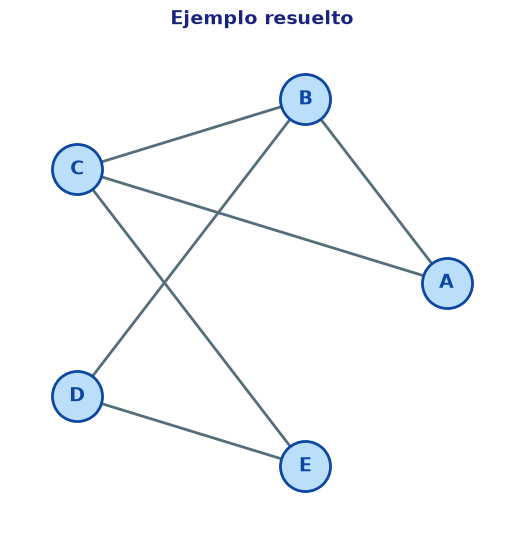

  ✔  n
  ✔  m
  ✔  grados
  ✔  vecinos de B
  ✔  aislados

  5 de 5 correctas


In [3]:
EJ = nx.Graph([('A', 'B'), ('A', 'C'), ('B', 'C'), ('B', 'D'), ('C', 'E'), ('D', 'E')])
dibujar(EJ, 'Ejemplo resuelto')

ej_n = 5
ej_m = 6
ej_grados = {'A': 2, 'B': 3, 'C': 3, 'D': 2, 'E': 2}
ej_vecinos_B = {'A', 'C', 'D'}
ej_aislados = set()

revisar([
    ('n', ej_n, EJ.number_of_nodes()),
    ('m', ej_m, EJ.number_of_edges()),
    ('grados', ej_grados, dict(EJ.degree())),
    ('vecinos de B', ej_vecinos_B, set(EJ.neighbors('B'))),
    ('aislados', ej_aislados, {v for v in EJ if EJ.degree(v) == 0}),
]);

## 1. Tu código de estudiante

Escribe tu código entre comillas, por ejemplo `CODIGO = '20261234'`, y ejecuta la celda. **No lo cambies después**: si lo cambias, cambian tus grafos.

In [4]:
CODIGO = '1010840910'    # <- tu código de estudiante, entre comillas

if CODIGO is None:
    raise ValueError('Escribe tu código de estudiante en CODIGO antes de continuar')
G, D, VND, VD = generar_grafos(str(CODIGO).strip())
print('Grafos generados para el código', CODIGO)
print('Vértice para las preguntas de vecinos:  no dirigido ->', VND, '   dirigido ->', VD)

Grafos generados para el código 1010840910
Vértice para las preguntas de vecinos:  no dirigido -> D    dirigido -> R


## 2. Grafo no dirigido

Ejecuta la celda para ver tu grafo.

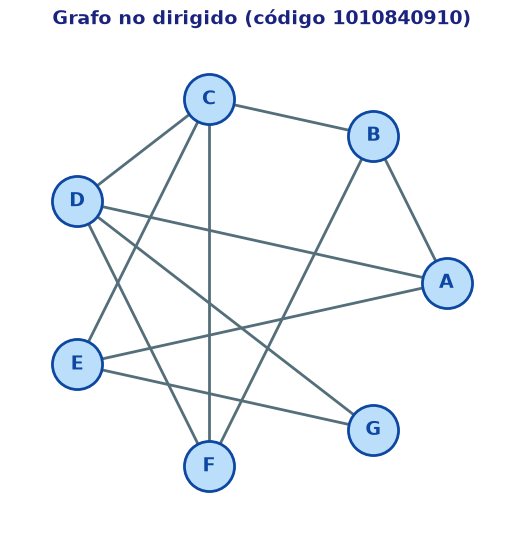

In [5]:
dibujar(G, f'Grafo no dirigido (código {CODIGO})')

**Preguntas.** Responde mirando el dibujo:

1. ¿Cuántos vértices tiene el grafo ($n$)?
2. ¿Cuántas aristas tiene el grafo ($m$)?
3. ¿Cuál es el grado de cada vértice?
4. ¿Cuánto vale la suma de todos los grados? (Compárala con $2m$.)
5. ¿Cuál es el grado **máximo** del grafo? ¿Qué vértices lo tienen?
6. ¿Qué vértices tienen grado **1** (hojas)? ¿Cuáles tienen grado **0** (aislados)?
7. ¿Cuáles son los **vecinos** del vértice indicado en la sección 1 (`VND`)?
8. ¿Cuántas aristas **más** se podrían agregar sin crear aristas paralelas ni lazos? (Recuerda: un grafo simple no dirigido tiene a lo sumo $n(n-1)/2$ aristas.)

In [6]:
nd_n = 7                   # 1. número de vértices
nd_m = 11                    # 2. número de aristas
nd_grados = {'A': 3, 'B': 3, 'C': 4, 'D': 4, 'E': 3, 'F': 3, 'G': 2}   # 3.
nd_suma_grados = 22          # 4. suma de los grados
nd_grado_max = 4            # 5. grado máximo
nd_vertices_max = {"C", "D"}         # 5. conjunto de vértices con el grado máximo, ej. {'A', 'C'}
nd_hojas = set()              # 6. conjunto de vértices de grado 1 (set() si no hay)
nd_aislados = set()             # 6. conjunto de vértices de grado 0 (set() si no hay)
nd_vecinos = 2            # 7. conjunto de vecinos de VND
nd_faltantes = 10            # 8. aristas que se podrían agregar

In [7]:
# --- Revisión: grafo no dirigido ---
_g = dict(G.degree())
_max = max(_g.values())
revisar([
    ('1. n', nd_n, G.number_of_nodes()),
    ('2. m', nd_m, G.number_of_edges()),
    ('3. grados', nd_grados, _g),
    ('4. suma de grados', nd_suma_grados, sum(_g.values())),
    ('5. grado máximo', nd_grado_max, _max),
    ('5. vértices con grado máximo', nd_vertices_max, {v for v in _g if _g[v] == _max}),
    ('6. hojas (grado 1)', nd_hojas, {v for v in _g if _g[v] == 1}),
    ('6. aislados (grado 0)', nd_aislados, {v for v in _g if _g[v] == 0}),
    (f'7. vecinos de {VND}', nd_vecinos, set(G.neighbors(VND))),
    ('8. aristas que faltan', nd_faltantes, len(G) * (len(G) - 1) // 2 - G.number_of_edges()),
]);

  ✔  1. n
  ✔  2. m
  ✔  3. grados
  ✔  4. suma de grados
  ✔  5. grado máximo
  ✔  5. vértices con grado máximo
  ✔  6. hojas (grado 1)
  ✔  6. aislados (grado 0)
  ✘  7. vecinos de D
  ✔  8. aristas que faltan

  9 de 10 correctas


## 3. Grafo dirigido

En el dibujo, cada flecha va del **origen** al **destino**. Si entre dos vértices hay dos flechas curvas, son dos aristas distintas: $u \to v$ y $v \to u$.

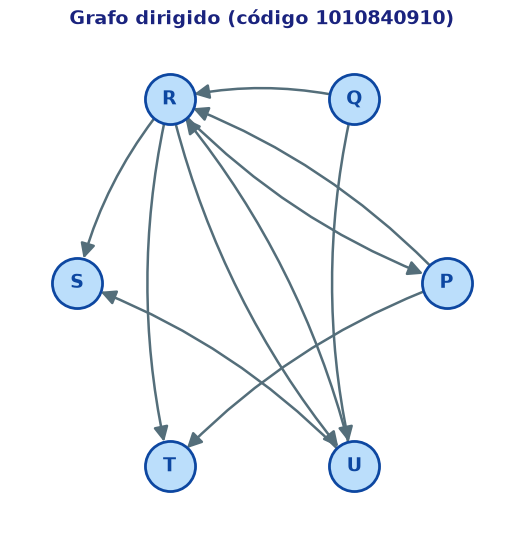

In [8]:
dibujar(D, f'Grafo dirigido (código {CODIGO})')

**Preguntas.** Responde mirando el dibujo:

1. ¿Cuántos vértices ($n$) y cuántas aristas ($m$) tiene el grafo?
2. ¿Cuál es el **grado de salida** ($\text{outdeg}$) de cada vértice?
3. ¿Cuál es el **grado de entrada** ($\text{indeg}$) de cada vértice?
4. ¿Cuánto vale la suma de los grados de salida? ¿Y la de los grados de entrada? (Compáralas con $m$.)
5. ¿Qué vértices son **fuentes** ($\text{indeg} = 0$)? ¿Cuáles son **sumideros** ($\text{outdeg} = 0$)?
6. Para el vértice indicado en la sección 1 (`VD`): ¿cuáles son sus **sucesores** (a dónde llegan sus flechas) y sus **predecesores** (de dónde vienen las flechas que llegan a él)?
7. ¿Qué vértice tiene el **mayor grado total** $\text{indeg}(v) + \text{outdeg}(v)$? Si hay empate, escribe todos en el conjunto.
8. ¿Qué pares de vértices están conectados **en los dos sentidos** ($u \to v$ y $v \to u$)? Escribe cada par como una cadena de dos letras en orden alfabético, por ejemplo `{'PQ', 'RT'}`.

In [9]:
d_n = None                     # 1. número de vértices
d_m = None                     # 1. número de aristas
d_out = {'P': None, 'Q': None, 'R': None, 'S': None, 'T': None, 'U': None}   # 2. outdeg
d_in  = {'P': None, 'Q': None, 'R': None, 'S': None, 'T': None, 'U': None}   # 3. indeg
d_suma_out = None              # 4. suma de los outdeg
d_suma_in = None               # 4. suma de los indeg
d_fuentes = None               # 5. conjunto de fuentes (set() si no hay)
d_sumideros = None             # 5. conjunto de sumideros (set() si no hay)
d_sucesores = None             # 6. conjunto de sucesores de VD
d_predecesores = None          # 6. conjunto de predecesores de VD
d_max_total = None             # 7. conjunto de vértices con mayor indeg + outdeg
d_dos_sentidos = None          # 8. conjunto de pares, ej. {'PQ', 'RT'} (set() si no hay)

In [10]:
# --- Revisión: grafo dirigido ---
_o, _i = dict(D.out_degree()), dict(D.in_degree())
_t = {v: _o[v] + _i[v] for v in D}
revisar([
    ('1. n', d_n, D.number_of_nodes()),
    ('1. m', d_m, D.number_of_edges()),
    ('2. outdeg', d_out, _o),
    ('3. indeg', d_in, _i),
    ('4. suma de outdeg', d_suma_out, sum(_o.values())),
    ('4. suma de indeg', d_suma_in, sum(_i.values())),
    ('5. fuentes', d_fuentes, {v for v in D if _i[v] == 0}),
    ('5. sumideros', d_sumideros, {v for v in D if _o[v] == 0}),
    (f'6. sucesores de {VD}', d_sucesores, set(D.successors(VD))),
    (f'6. predecesores de {VD}', d_predecesores, set(D.predecessors(VD))),
    ('7. mayor grado total', d_max_total, {v for v in D if _t[v] == max(_t.values())}),
    ('8. pares en los dos sentidos', d_dos_sentidos,
     {''.join(sorted((u, v))) for u, v in D.edges() if D.has_edge(v, u)}),
]);

  …  1. n: sin responder
  …  1. m: sin responder
  …  2. outdeg: sin responder
  …  3. indeg: sin responder
  …  4. suma de outdeg: sin responder
  …  4. suma de indeg: sin responder
  …  5. fuentes: sin responder
  …  5. sumideros: sin responder
  …  6. sucesores de R: sin responder
  …  6. predecesores de R: sin responder
  …  7. mayor grado total: sin responder
  …  8. pares en los dos sentidos: sin responder

  0 de 12 correctas


## 4. Para pensar (respuesta escrita)

**1. En tu grafo no dirigido, ¿por qué la suma de los grados siempre es par?**

Cada arista $\{u, v\}$ toca exactamente a dos vértices: suma 1 al grado de $u$ y 1 al grado de $v$. Entonces cada arista aporta exactamente 2 a la suma total y
$$\sum_v \deg(v) = 2m.$$
En mi grafo: $3+3+4+4+3+3+2 = 22 = 2 \cdot 11$. No depende del dibujo, solo de cuántas aristas hay.

**2. En tu grafo dirigido, ¿por qué la suma de los outdeg es igual a la suma de los indeg?**

Cada arista dirigida $u \to v$ **sale** de un solo vértice ($+1$ a $\text{outdeg}(u)$) y **llega** a un solo vértice ($+1$ a $\text{indeg}(v)$). Al sumar, cada arista se cuenta una vez en cada suma:
$$\sum_v \text{outdeg}(v) = \sum_v \text{indeg}(v) = m.$$
En mi grafo ambas sumas valen $10 = m$.

**3. Si cada arista $\{u, v\}$ se reemplaza por $u \to v$ y $v \to u$, ¿qué relación hay entre $\deg(v)$ y $\text{indeg}(v)$, $\text{outdeg}(v)$?**

Cada arista que tocaba a $v$ produce exactamente una flecha que sale de $v$ y una que llega a $v$. Por eso
$$\text{indeg}(v) = \text{outdeg}(v) = \deg(v), \qquad \text{indeg}(v) + \text{outdeg}(v) = 2\deg(v),$$
y el grafo dirigido tiene $2m$ aristas.

**4. En la clase `Graph` de Goodrich, ¿qué llamada da el grado de entrada de `v`? ¿Por qué en un no dirigido `G.degree(v)` y `G.degree(v, False)` dan lo mismo?**

El grado de entrada es `G.degree(v, False)` (el parámetro `outgoing=False` hace que cuente en el mapa `_incoming`); el grado de salida es `G.degree(v)`.

En un grafo no dirigido el constructor hace `self._incoming = {} if directed else self._outgoing`: `_incoming` **es el mismo diccionario** que `_outgoing` (un alias, no una copia). Las dos llamadas miran el mismo mapa de adyacencia, así que dan el mismo número.

## 5. Punto adicional: construye tu grafo con la clase `Graph` de Goodrich

Ahora vas a construir **tú mismo** el grafo **no dirigido** de la sección 2, usando la clase `Graph` del libro (`goodrich/ch14/graph.py`). Cada estudiante construye **su propio** grafo, mirando su dibujo.

1. Importa la clase con `from goodrich.ch14.graph import Graph` (ejecuta la celda siguiente).
2. Crea un grafo no dirigido: `GG = Graph()`.
3. Inserta los 7 vértices con `GG.insert_vertex(x)`, usando la letra como elemento (`'A'`, `'B'`, …). `insert_vertex` **retorna** el objeto `Vertex`: guárdalo en el diccionario `V`, por ejemplo `V['A'] = GG.insert_vertex('A')`.
4. Inserta cada arista de tu dibujo con `GG.insert_edge(V['A'], V['B'])`. Ojo: `insert_edge` recibe objetos `Vertex`, **no** letras.

No uses `G` (el grafo de `networkx`) ni ciclos sobre sus aristas para construirlo: escríbelo mirando el dibujo. Luego ejecuta la celda de revisión.


In [11]:
import sys
from pathlib import Path

# Busca hacia arriba la carpeta que contiene goodrich/ (funciona en Codespaces y en local)
_raiz = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'goodrich' / 'ch14' / 'graph.py').exists())
if str(_raiz) not in sys.path:
    sys.path.append(str(_raiz))

from goodrich.ch14.graph import Graph

In [12]:
GG = Graph()   # grafo no dirigido
V = {}         # diccionario letra -> Vertex

# --- vértices (A a G) ---
V['A'] = GG.insert_vertex('A')
V['B'] = GG.insert_vertex('B')
V['C'] = GG.insert_vertex('C')
V['D'] = GG.insert_vertex('D')
V['E'] = GG.insert_vertex('E')
V['F'] = GG.insert_vertex('F')
V['G'] = GG.insert_vertex('G')

# --- aristas de mi dibujo (11) ---
GG.insert_edge(V['A'], V['B'])
GG.insert_edge(V['A'], V['D'])
GG.insert_edge(V['A'], V['E'])
GG.insert_edge(V['B'], V['C'])
GG.insert_edge(V['B'], V['F'])
GG.insert_edge(V['C'], V['D'])
GG.insert_edge(V['C'], V['E'])
GG.insert_edge(V['C'], V['F'])
GG.insert_edge(V['D'], V['F'])
GG.insert_edge(V['D'], V['G'])
GG.insert_edge(V['E'], V['G'])

print('vértices:', GG.vertex_count(), ' aristas:', GG.edge_count())

vértices: 7  aristas: 11


In [13]:
# --- Revisión: grafo construido con Goodrich ---
if not isinstance(GG, Graph):
    raise TypeError('GG debe ser un objeto Graph de Goodrich')
_gg_grados = {v.element(): GG.degree(v) for v in GG.vertices()}
_gg_aristas = {''.join(sorted(str(x) for x in (u.element(), w.element()))) for u, w in (e.endpoints() for e in GG.edges())}
revisar([
    ('es no dirigido', GG.is_directed(), False),
    ('vértices', {v.element() for v in GG.vertices()}, set(G.nodes())),
    ('número de aristas (edge_count)', GG.edge_count(), G.number_of_edges()),
    ('aristas', _gg_aristas, {''.join(sorted(e)) for e in G.edges()}),
    ('grados (degree)', _gg_grados, dict(G.degree())),
]);


  ✔  es no dirigido
  ✔  vértices
  ✔  número de aristas (edge_count)
  ✔  aristas
  ✔  grados (degree)

  5 de 5 correctas


## 6. Caminata aleatoria sobre tu grafo

Una persona está parada en el vértice `VND` (el de la sección 1) de **tu grafo no dirigido** `GG` (el que construiste en la sección 5) y hace una **caminata aleatoria de 7 pasos**:

- En cada paso **siempre cambia de vértice**: se mueve a uno de los **vecinos** del vértice donde está.
- Todos los vecinos tienen la **misma probabilidad** de ser elegidos. Si el vértice tiene grado $d$, cada vecino se elige con probabilidad $1/d$.

**Pregunta:** después de los 7 pasos, ¿en qué vértice es **más probable** que termine la persona?

Para responder, programa dos funciones usando **solo la interfaz de Goodrich** (`incident_edges(v)`, `e.opposite(v)`, `degree(v)`, `v.element()`):

1. `caminata(grafo, inicio, pasos)`: hace **una** caminata aleatoria de `pasos` pasos desde el vértice `inicio` y retorna el `Vertex` donde termina. Sugerencia: `random.choice(list(...))` elige un elemento al azar de una lista.
2. `frecuencias(grafo, inicio, pasos, repeticiones)`: repite la caminata `repeticiones` veces y retorna un diccionario `{letra: fracción de caminatas que terminan en esa letra}`. Las fracciones deben sumar 1.

Luego ejecuta la simulación, mira las frecuencias y responde en `cam_mas_probable` el **conjunto** de vértices donde es más probable terminar. Como la simulación tiene algo de ruido, si varios vértices tienen frecuencias **casi iguales** a la mayor (diferencia menor que `0.005`), escríbelos todos.

**Para pensar:** ¿hay vértices donde la persona **nunca** termina después de 7 pasos? ¿Por qué? ¿Qué pasaría con un número par de pasos?


In [14]:
import random


def caminata(grafo, inicio, pasos):
    """Hace una caminata aleatoria de `pasos` pasos desde `inicio` y retorna el Vertex donde termina."""
    actual = inicio
    for _ in range(pasos):
        vecinos = [e.opposite(actual) for e in grafo.incident_edges(actual)]
        actual = random.choice(vecinos)          # cada vecino con probabilidad 1/degree(actual)
    return actual


def frecuencias(grafo, inicio, pasos, repeticiones):
    """Repite la caminata y retorna {letra: fracción de caminatas que terminan en esa letra}."""
    conteo = {}
    for _ in range(repeticiones):
        letra = caminata(grafo, inicio, pasos).element()
        conteo[letra] = conteo.get(letra, 0) + 1
    for letra in conteo:
        conteo[letra] /= repeticiones            # de conteos a fracciones (suman 1)
    return conteo

In [15]:
PASOS = 7
REPETICIONES = 100_000

inicio = next(v for v in GG.vertices() if v.element() == VND)
frec = frecuencias(GG, inicio, PASOS, REPETICIONES)
print(f'Caminatas de {PASOS} pasos desde {VND} ({REPETICIONES} repeticiones):')
for letra in sorted(frec):
    print(f'  {letra}: {frec[letra]:.4f}')

_mx = max(frec.values())
print('\nCasi máximos (diferencia < 0.005):', {v for v in frec if frec[v] > _mx - 0.005})

cam_mas_probable = {'C'}       # conjunto de vértices donde es más probable terminar

Caminatas de 7 pasos desde D (100000 repeticiones):
  A: 0.2092
  B: 0.0806
  C: 0.2448
  D: 0.0966
  E: 0.0626
  F: 0.1631
  G: 0.1430

Casi máximos (diferencia < 0.005): {'C'}


In [16]:
# --- Revisión: caminata aleatoria ---
def _distribucion_exacta(pasos):
    p = {VND: 1.0}
    for _ in range(pasos):
        q = {}
        for v, pv in p.items():
            for u in G.neighbors(v):
                q[u] = q.get(u, 0) + pv / G.degree(v)
        p = q
    return p

_exacta = _distribucion_exacta(PASOS)


def _respuesta_caminata(resp):
    """Acepta el conjunto si incluye todos los máximos exactos y solo vértices casi máximos (por el ruido de la simulación)."""
    if resp is None:
        return None
    resp = _normalizar(resp)
    _mx = max(_exacta.values())
    maximos = {v for v in _exacta if _exacta[v] > _mx - 1e-12}
    casi = {v for v in _exacta if _exacta[v] > _mx - 0.01}
    return maximos <= resp <= casi

_vecinos = {u.element() for u in (e.opposite(inicio) for e in GG.incident_edges(inicio))}
_un_paso = [caminata(GG, inicio, 1) for _ in range(300)]
_frec = frec if isinstance(frec, dict) else {}
revisar([
    ('caminata de 0 pasos se queda en el inicio', caminata(GG, inicio, 0) is inicio, True),
    ('caminata de 1 paso termina en un vecino',
     all(isinstance(x, Graph.Vertex) and x.element() in _vecinos for x in _un_paso), True),
    ('frecuencias suman 1', abs(sum(_frec.values()) - 1) < 1e-9, True),
    ('frecuencias cercanas a las probabilidades reales',
     max((abs(_frec.get(v, 0) - _exacta.get(v, 0)) for v in G), default=1) < 0.01, True),
    ('vértice(s) más probable(s)', _respuesta_caminata(cam_mas_probable), True),
]);


  ✔  caminata de 0 pasos se queda en el inicio
  ✔  caminata de 1 paso termina en un vecino
  ✔  frecuencias suman 1
  ✔  frecuencias cercanas a las probabilidades reales
  ✔  vértice(s) más probable(s)

  5 de 5 correctas


**Para pensar — caminata aleatoria**

- **Respuesta:** el vértice más probable es **C** (probabilidad exacta ≈ 0.244), seguido de A (≈ 0.209). La diferencia es mucho mayor que 0.005, así que el conjunto es solo `{'C'}`.
- **¿Hay vértices donde nunca termina después de 7 pasos?** **No.** En mi grafo todos los vértices tienen probabilidad positiva (el menor es E ≈ 0.062). La razón es que el grafo **no es bipartito**: tiene ciclos de longitud impar, por ejemplo el triángulo $B - C - F - B$ (y también $C - D - F - C$). Dando una vuelta a un triángulo la persona puede “ajustar la paridad” y llegar a cualquier vértice tanto en un número par como impar de pasos.
  - En un grafo **bipartito** (sin ciclos impares) sí pasaría: cada paso cambia de lado, y con 7 pasos (impar) nunca se termina en el lado del vértice inicial.
  - Ojo: con **1 paso** sí hay vértices imposibles (solo se llega a los vecinos de D: A, C, F, G), y con 2 pasos tampoco se llega a A ni a G. Con 7 pasos ya hay caminos de esa longitud hacia todos.
- **¿Y con un número par de pasos?** En este grafo, por tener ciclos impares, con 8 pasos también se puede terminar en cualquier vértice; cambia cuál es el más probable (con 8 pasos es **D**, ≈ 0.257, porque los caminos pares favorecen volver cerca del inicio). Si el grafo fuera bipartito, con pasos pares se terminaría siempre en el mismo lado del inicio. Con muchos pasos la probabilidad tiende a $\deg(v)/2m$, así que a la larga ganan C y D (grado 4 → $4/22 \approx 0.18$).

# Preguntas Dijistra y distancias

## 7. Punto adicional: construye a mano un grafo con pesos usando `Graph` de Goodrich

Ahora recibes la **imagen** de un grafo **no dirigido con pesos** (cada arista tiene un número: su peso). También es **único para cada estudiante**: depende de tu `CODIGO`.

Tu tarea es construirlo **a mano** con la clase `Graph` de Goodrich (`goodrich/ch14/graph.py`), mirando solo el dibujo:

1. Ejecuta la celda de herramientas y la celda que dibuja el grafo.
2. Crea el grafo con `GW = Graph()` (no dirigido).
3. Inserta los 7 vértices con `GW.insert_vertex(x)` y guarda cada `Vertex` en el diccionario `VW`, por ejemplo `VW['A'] = GW.insert_vertex('A')`.
4. Inserta cada arista **con su peso** usando el tercer parámetro de `insert_edge`, que es el *elemento* de la arista: `GW.insert_edge(VW['A'], VW['B'], 7)`. Recuerda que `insert_edge` recibe objetos `Vertex`, **no** letras.
5. Ejecuta la celda de revisión.

No uses `GP` (el grafo de `networkx`) ni ciclos sobre sus aristas para construirlo: escríbelo mirando el dibujo. Una vez construido, el peso de una arista se lee con `GW.get_edge(u, v).element()`.

In [17]:
from goodrich.ch14.graph import *

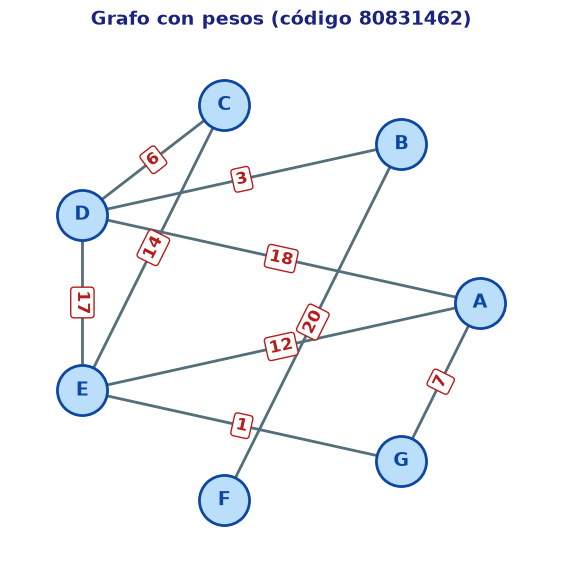

In [18]:
# --- Herramientas (no modificar): genera y dibuja tu grafo con pesos ---
ETIQUETAS_W = list('ABCDEFG')      # 7 vértices


def generar_grafo_pesos(codigo):
    """Retorna un grafo de networkx no dirigido, conexo, con pesos enteros (1 a 20) en el atributo 'weight'."""
    rng = random.Random(f'ch14-pesos-{codigo}')
    GP = nx.Graph()
    GP.add_nodes_from(ETIQUETAS_W)
    # árbol de expansión aleatorio (garantiza que el grafo sea conexo)
    orden = ETIQUETAS_W[:]
    rng.shuffle(orden)
    for i in range(1, len(orden)):
        GP.add_edge(orden[i], rng.choice(orden[:i]))
    # aristas adicionales hasta tener entre 9 y 11 en total
    posibles = [(u, v) for i, u in enumerate(ETIQUETAS_W) for v in ETIQUETAS_W[i + 1:] if not GP.has_edge(u, v)]
    GP.add_edges_from(rng.sample(posibles, rng.randint(9, 11) - GP.number_of_edges()))
    for u, v in GP.edges():
        GP[u][v]['weight'] = rng.randint(1, 20)
    return GP


def dibujar_pesos(grafo, titulo):
    """Dibuja el grafo con los vértices en círculo y el peso escrito sobre cada arista."""
    pos = nx.circular_layout(sorted(grafo.nodes()))
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.set_title(titulo, fontsize=14, fontweight='bold', color='#1A237E')
    nx.draw_networkx_edges(grafo, pos, ax=ax, edge_color='#546E7A', width=2.0, node_size=1300)
    nx.draw_networkx_nodes(grafo, pos, ax=ax, node_color='#BBDEFB', edgecolors='#0D47A1',
                           linewidths=2, node_size=1300)
    nx.draw_networkx_labels(grafo, pos, ax=ax, font_size=14, font_weight='bold', font_color='#0D47A1')
    nx.draw_networkx_edge_labels(grafo, pos, ax=ax, edge_labels=nx.get_edge_attributes(grafo, 'weight'),
                                 font_size=12, font_weight='bold', font_color='#B71C1C',
                                 bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='#B71C1C', lw=1))
    ax.margins(0.12)
    ax.axis('off')
    plt.show()


CODIGO = 80831462
GP = generar_grafo_pesos(str(CODIGO).strip())
dibujar_pesos(GP, f'Grafo con pesos (código {CODIGO})')

In [19]:
GW = Graph()   # grafo no dirigido con pesos
VW = {}        # diccionario letra -> Vertex

# --- vértices (A a G) ---
VW['A'] = GW.insert_vertex('A')
VW['B'] = GW.insert_vertex('B')
VW['C'] = GW.insert_vertex('C')
VW['D'] = GW.insert_vertex('D')
VW['E'] = GW.insert_vertex('E')
VW['F'] = GW.insert_vertex('F')
VW['G'] = GW.insert_vertex('G')

# --- aristas del dibujo con su peso (9) ---
GW.insert_edge(VW['A'], VW['D'], 18)
GW.insert_edge(VW['A'], VW['E'], 12)
GW.insert_edge(VW['A'], VW['G'], 7)
GW.insert_edge(VW['B'], VW['D'], 3)
GW.insert_edge(VW['B'], VW['F'], 20)
GW.insert_edge(VW['C'], VW['D'], 6)
GW.insert_edge(VW['C'], VW['E'], 14)
GW.insert_edge(VW['D'], VW['E'], 17)
GW.insert_edge(VW['E'], VW['G'], 1)

print('vértices:', GW.vertex_count(), ' aristas:', GW.edge_count())
print('peso A-D:', GW.get_edge(VW['A'], VW['D']).element())

vértices: 7  aristas: 9
peso A-D: 18


In [20]:
# --- Revisión: grafo con pesos construido con Goodrich ---
if not isinstance(GW, Graph):
    raise TypeError('GW debe ser un objeto Graph de Goodrich')
_clave = lambda a, b: ''.join(sorted((str(a), str(b))))
_gw_aristas = {_clave(*(x.element() for x in e.endpoints())): e.element() for e in GW.edges()}
_gp_aristas = {_clave(u, v): w for u, v, w in GP.edges(data='weight')}
revisar([
    ('es no dirigido', GW.is_directed(), False),
    ('vértices', {v.element() for v in GW.vertices()}, set(GP.nodes())),
    ('número de aristas (edge_count)', GW.edge_count(), GP.number_of_edges()),
    ('aristas', set(_gw_aristas), set(_gp_aristas)),
    ('pesos de las aristas', _gw_aristas, _gp_aristas),
    ('grados (degree)', {v.element(): GW.degree(v) for v in GW.vertices()}, dict(GP.degree())),
]);

  ✔  es no dirigido
  ✔  vértices
  ✔  número de aristas (edge_count)
  ✔  aristas
  ✔  pesos de las aristas
  ✔  grados (degree)

  6 de 6 correctas


## Preguntas: Dijkstra y distancias

Todas se responden sobre el grafo con pesos `GW` de la sección 7, usando la implementación de Goodrich (`goodrich/ch14/shortest_paths.py`):

- `shortest_path_lengths(g, s)` → diccionario `{Vertex: distancia mínima desde s}`.
- `shortest_path_tree(g, s, d)` → diccionario `{Vertex v: arista e}`, donde `e` es la arista que llega a `v` desde su **padre** en el árbol de caminos mínimos.

Cada pregunta tiene su propia función pequeña. Cambia `INICIO` para usar otro vértice inicial.

### 1. Ejecutar Dijkstra desde un vértice dado

In [21]:
from goodrich.ch14.shortest_paths import shortest_path_lengths, shortest_path_tree

INICIO = 'A'                 # <- vértice inicial (puedes cambiarlo)
s = VW[INICIO]

dist = shortest_path_lengths(GW, s)          # {Vertex: distancia}
arbol = shortest_path_tree(GW, s, dist)      # {Vertex hijo: arista desde su padre}

print(f'Distancias mínimas desde {INICIO}:')
for v in sorted(dist, key=lambda x: x.element()):
    print(f'  {v.element()}: {dist[v]}')

Distancias mínimas desde A:
  A: 0
  B: 21
  C: 22
  D: 18
  E: 8
  F: 41
  G: 7


### 2. Distancia promedio desde el vértice inicial a los otros vértices

In [22]:
def distancia_promedio(dist, s):
    """Promedio de las distancias de s a los DEMÁS vértices (no cuenta la distancia 0 a sí mismo)."""
    otros = [d for v, d in dist.items() if v is not s]
    return sum(otros) / len(otros)


print(f'Distancia promedio desde {INICIO}: {distancia_promedio(dist, s):.4f}')

Distancia promedio desde A: 19.5000


### 3. El árbol de Dijkstra: hojas, número promedio de hijos y altura

Primero se convierte el diccionario `{hijo: arista}` en `{padre: [hijos]}`. El padre de `v` es el otro extremo de su arista: `e.opposite(v)`.

- **Hoja:** vértice sin hijos.
- **Promedio de hijos:** total de hijos ÷ número de nodos **internos** (los que tienen al menos un hijo). Como referencia también se muestra el promedio sobre todos los nodos, que siempre es $(n-1)/n$.
- **Altura:** número de aristas del camino más largo desde la raíz hasta una hoja (en niveles, no en pesos).

In [23]:
def hijos_por_nodo(arbol, raiz):
    """Retorna {Vertex: [hijos]} para todos los vértices del árbol (incluye la raíz)."""
    hijos = {raiz: []}
    for v in arbol:
        hijos.setdefault(v, [])
    for v, e in arbol.items():
        padre = e.opposite(v)
        hijos[padre].append(v)
    return hijos


def hojas(hijos):
    return {v.element() for v, h in hijos.items() if len(h) == 0}


def promedio_hijos(hijos):
    internos = [h for h in hijos.values() if len(h) > 0]
    return sum(len(h) for h in internos) / len(internos)


def altura(hijos, v):
    """Altura del subárbol con raíz v (0 si v es hoja)."""
    if not hijos[v]:
        return 0
    return 1 + max(altura(hijos, h) for h in hijos[v])


H = hijos_por_nodo(arbol, s)

print('Árbol de caminos mínimos (padre -> hijos):')
for v in sorted(H, key=lambda x: x.element()):
    print(f'  {v.element()} -> {sorted(h.element() for h in H[v])}')

print('\nHojas:', sorted(hojas(H)))
print(f'Promedio de hijos (nodos internos): {promedio_hijos(H):.4f}')
print(f'Promedio de hijos (todos los nodos): {(len(H) - 1) / len(H):.4f}')
print('Altura del árbol:', altura(H, s))

Árbol de caminos mínimos (padre -> hijos):
  A -> ['D', 'G']
  B -> ['F']
  C -> []
  D -> ['B']
  E -> ['C']
  F -> []
  G -> ['E']

Hojas: ['C', 'F']
Promedio de hijos (nodos internos): 1.2000
Promedio de hijos (todos los nodos): 0.8571
Altura del árbol: 3


### 4. El vértice más lejano desde el vértice inicial

In [24]:
def mas_lejano(dist):
    """Conjunto de vértices con la mayor distancia (por si hay empate) y esa distancia."""
    d_max = max(dist.values())
    return {v.element() for v, d in dist.items() if d == d_max}, d_max


lejanos, d_max = mas_lejano(dist)
print(f'Más lejano(s) desde {INICIO}: {lejanos}  (distancia {d_max})')

Más lejano(s) desde A: {'F'}  (distancia 41)


### 5. Los hijos de un nodo determinado (en el árbol de Dijkstra)

In [25]:
def hijos_de(hijos, letra):
    v = VW[letra]
    return sorted(h.element() for h in hijos[v])


NODO = 'E'                   # <- nodo a consultar (puedes cambiarlo)
print(f'Hijos de {NODO}:', hijos_de(H, NODO))

for letra in sorted(VW):
    print(f'  hijos de {letra}: {hijos_de(H, letra)}')

Hijos de E: ['C']
  hijos de A: ['D', 'G']
  hijos de B: ['F']
  hijos de C: []
  hijos de D: ['B']
  hijos de E: ['C']
  hijos de F: []
  hijos de G: ['E']


### 6. Caminata aleatoria hasta llegar a un vértice dado

Desde `INICIO`, en cada paso se va a un vecino elegido al azar (igual que en la sección 6) hasta llegar a `DESTINO`. Retorna el camino recorrido como lista de letras (puede repetir vértices). Como el grafo es conexo, la caminata siempre termina.

In [26]:
def caminata_hasta(grafo, inicio, destino):
    """Camina al azar desde `inicio` hasta llegar a `destino`; retorna la lista de letras visitadas."""
    actual = inicio
    camino = [actual.element()]
    while actual is not destino:
        vecinos = [e.opposite(actual) for e in grafo.incident_edges(actual)]
        actual = random.choice(vecinos)
        camino.append(actual.element())
    return camino


DESTINO = 'F'                # <- vértice al que se quiere llegar
camino = caminata_hasta(GW, VW[INICIO], VW[DESTINO])
print(f'Camino de {INICIO} a {DESTINO} ({len(camino) - 1} pasos):')
print(' -> '.join(camino))

Camino de A a F (67 pasos):
A -> D -> A -> G -> E -> D -> E -> C -> E -> C -> E -> C -> E -> C -> E -> A -> D -> E -> G -> E -> C -> E -> D -> C -> D -> E -> C -> E -> G -> E -> D -> E -> D -> B -> D -> C -> D -> A -> D -> C -> D -> C -> D -> B -> D -> E -> D -> C -> E -> G -> E -> G -> A -> D -> E -> A -> D -> B -> D -> A -> E -> G -> A -> D -> B -> D -> B -> F
